In [11]:
import nafusion_utils.daq as daq
import matplotlib.pyplot as plt
import nafusion_utils as na
import numpy as np
import nafusion_utils.polyspectrum as ps
import matplotlib.colors as mc
import os
na.set_style()
%matplotlib widget



In [12]:
def read_we(_shot, tower, station, ch):
    return daq.read_wvf(
        path + f"/WE7000/{str(_shot).zfill(6)}/{tower}_{station}_{str(ch).zfill(2)}.wvf", digitizer="WE7000"
    )


# path = "/Volumes/data/expdata"  # <<===
path = "/Volumes/Artemis/SPHINX/misc/2609_PANTA_experiment"  # <<===

Text(0, 0.5, 'fluctuation')

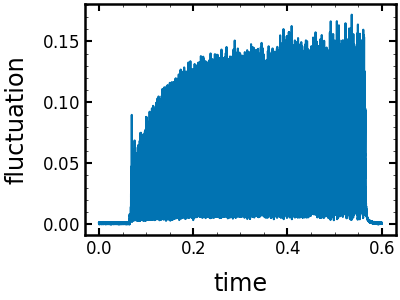

In [13]:
shot = 19490
data = read_we(shot, 2, 1, 1)
plt.figure()
data.plot()
plt.ylabel("fluctuation")
#data

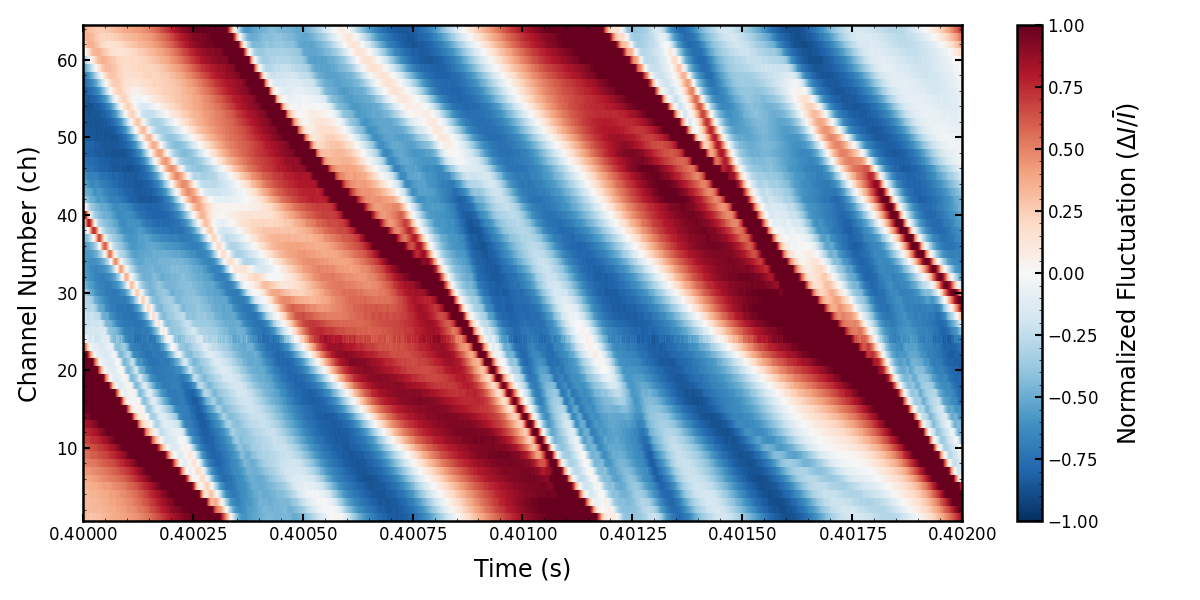

In [14]:

start = 0.4
end = 0.402
dt = 1e-6  

all_data = []

for i in range(2, 4):          
    for j in range(1, 4):
        if i == 3 and j >= 2:
            continue
            
        for k in range(1, 17): 
            data = read_we(shot, i, j, k)
            all_data.append(data)

data_matrix = np.array(all_data)
num_ch, num_time = data_matrix.shape


idx_start = int(start / dt)
idx_end = int(end / dt)

time_axis = np.arange(num_time) * dt
sliced_time = time_axis[idx_start:idx_end]
sliced_data = data_matrix[:, idx_start:idx_end]

mean_array = np.mean(sliced_data, axis=1, keepdims=True)


norm_data = (sliced_data - mean_array) / mean_array

ch_axis = np.arange(1, num_ch + 1)

plt.figure(figsize=(12, 6), layout='tight')

vmax_val = np.max(np.abs(norm_data))

c_min = -1
c_max = 1

mesh = plt.pcolormesh(
    sliced_time, 
    ch_axis, 
    norm_data, 
    cmap='RdBu_r', 
    vmin=c_min,    # 最小値を固定
    vmax=c_max,    # 最大値を固定
    shading='auto'
)


plt.colorbar(mesh, label='Normalized Fluctuation ($\\Delta I / \\bar{I}$)')

plt.xlabel('Time (s)')
plt.ylabel('Channel Number (ch)')
plt.xlim(start, end)


plt.show()






# 64ch


In [15]:
s, e = 0.1, 0.2
shot = 19480
sig_64ch = []
for i in range(1, 4):
    for j in range(1, 17):
        da = read_we(str(shot).zfill(6), 2, i, j).sel(time=slice(s, e))
        sig_64ch.append(da / da.mean() - 1)
for j in range(1, 17):
    da = read_we(str(shot).zfill(6), 3, 1, j).sel(time=slice(s, e))
    sig_64ch.append(da / da.mean() - 1)
sig_64ch = np.array(sig_64ch)

[]

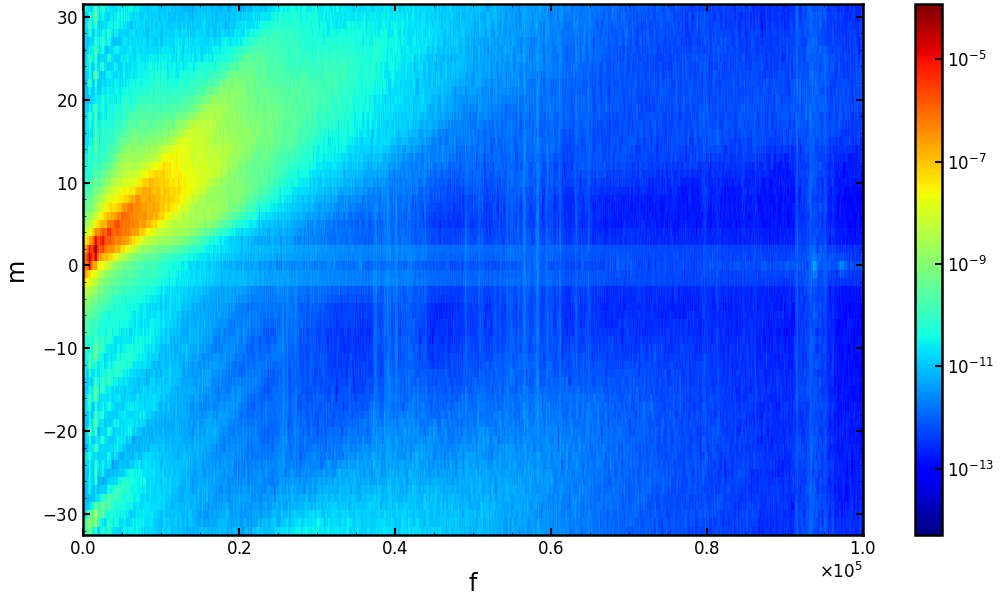

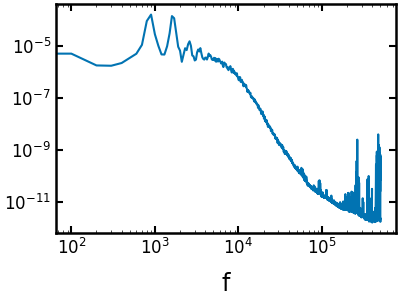

In [19]:
plt.figure(figsize=(10, 6))
# plt.pcolormesh(sig_64ch, cmap="jet")
psd_2d = ps.PSD_2d(sig_64ch, mode="64ch")
psd_2d.plot(norm=mc.LogNorm(), cmap="jet")
plt.xlim(0, 1e5)
save_dir = '/Users/kobarahayato/workplace/notebooks/analysis/figure_09'
file_path = os.path.join(save_dir, f'{shot}.pdf')
plt.savefig(file_path)

plt.figure()
psd_2d.sum("m").plot()
plt.loglog()
# save_dir = '/Users/kobarahayato/workplace/notebooks/analysis/figure_09'
# file_path = os.path.join(save_dir, f'{shot}.png')
# plt.savefig(file_path)

# ps.PSD_2d(sig_64ch[1::2], mode="32ch").plot(norm=mc.LogNorm(), cmap="jet")
# for i in range(64)[20:50]:
#     ps.PSD(sig_64ch[i]).plot()
# plt.loglog()

一次元

/var/folders/xq/kggsfjyx4hd000vc2qj79bpw0000gn/T/ipykernel_380/2474688590.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/data/expdata/DL950/019000/019380/019380_DL950_0000.hdr'

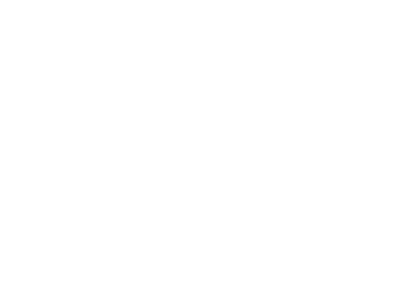

In [20]:
# path = "/Users/kawachi/Library/CloudStorage/SynologyDrive-mercury/Research/experiment/exp_data/PANTA/2609"
path = "/Volumes/data/expdata"  # <<===
# /Volumes/data/expdata/DL950/019000


plt.figure()
for i in [19380]:
    shot = i
    zshot = str(shot).zfill(6)
    DLNAME = path + f"/DL950/019000/{zshot}/{zshot}_DL950_0000.wvf"
    dl = daq.read_wvf(DLNAME, digitizer="DL950").sel(time=slice(0.3, 0.5))
    Vf1 = dl.CH1_1 - dl.CH1_1.mean()
    Vf2 = dl.CH2_1 - dl.CH2_1.mean()
Ey = Vf1 - Vf2

plt.plot(Ey)
#     ps.PSD((Vf1 - Vf2).data, fs=2e6).plot(label=f"shot={shot}")
# # ps.PSD(dl.CH1_1.sel(time=slice(0, 0.05)).data, fs=2e6).plot(label=f"shot={shot}")

# # ps.CSD(dl.CH1_1.sel(time=slice(0.4, 0.5)).data, dl.CH1_2.sel(time=slice(0.4, 0.5)).data, fs=2e6).squared_coherence.plot()
# plt.loglog()
# # plt.xscale("log")

[]

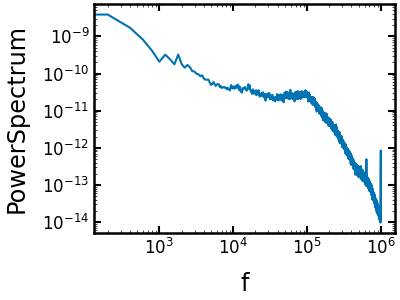

In [28]:
plt.figure()
ps.PSD(dl.CH1_2.sel(time=slice(0.3, 0.5)).data, fs=2e6).plot(label="sig_64ch[0]")
plt.loglog()

[]

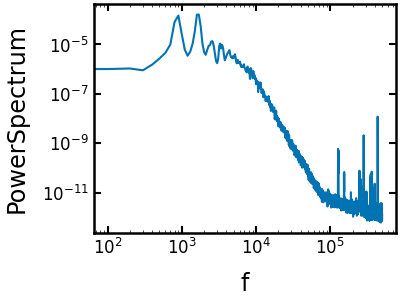

In [29]:
plt.figure()
ps.PSD(sig_64ch[0]).plot()

plt.loglog()